# Capítulo 23 — Regressão logística simples: idade e doença coronária (Caso 1)

**MBA em IA & Big Data (ICMC-USP) · Curso 4 — Estatística · Material de estudo**

> **Fonte do caso.** Este notebook reproduz e expande o exemplo do post
> *"Regressão Logística Simples: Aplicação no Python (Caso 1)"*, de Paula Gouveia, publicado pela
> **Statplace** em 25/02/2025: <https://statplace.com.br/blog/regressao-logistica-caso1/>.
> O banco, a pergunta e a sequência da análise vêm de lá; o texto, os acréscimos (teste da razão de
> verossimilhanças, IC por verossimilhança perfilada, curva ajustada com banda de confiança, discussão OR × RR)
> e eventuais erros são deste material.

**Pergunta clínica.** Em uma amostra de 100 adultos, a idade está associada à presença de doença coronária
(CHD, *coronary heart disease*)? Se sim, de quanto é essa associação e como expressá-la de forma correta?

**O que você vai praticar**

1. Carregar um banco público e recodificar o desfecho binário para 0/1.
2. Descrever os dados e enxergar a relação idade × CHD (dispersão e proporções por faixa etária).
3. Ajustar a regressão logística com `statsmodels` (`smf.logit` e `smf.glm` com família Binomial).
4. Interpretar coeficientes como **log-odds** e transformá-los em **razão de chances** (OR = e<sup>β</sup>) com IC 95%.
5. Testar a associação (Wald e razão de verossimilhanças) e obter probabilidades preditas.
6. Entender por que, com desfecho frequente (aqui 43%), **OR não é risco relativo**.

## 1. Ambiente

A célula abaixo instala o que faltar e importa as bibliotecas. No Google Colab, `pandas`, `numpy`,
`statsmodels`, `scipy` e `matplotlib` já vêm instalados; só o `pyreadr` (leitor de arquivos `.rda` do R,
sem precisar do R instalado) é baixado. O post original usava `rpy2` para isso, o que exige o R na máquina —
o `pyreadr` evita essa dependência.

In [1]:
# Instala apenas o que estiver faltando (roda igual no Colab e em máquina local)
import importlib, subprocess, sys
for pacote in ["pyreadr", "statsmodels"]:
    if importlib.util.find_spec(pacote) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import tempfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyreadr
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats, optimize

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("statsmodels", sm.__version__, "| pandas", pd.__version__)

statsmodels 0.15.0 | pandas 3.1.1


## 2. Os dados: CHDAGE (Hosmer, Lemeshow & Sturdivant)

O banco **CHDAGE** é o exemplo de abertura do livro *Applied Logistic Regression* (Hosmer, Lemeshow &
Sturdivant, 3ª ed., 2013). São 100 indivíduos com quatro variáveis:

| Variável | Descrição |
|---|---|
| `id` | identificador do indivíduo |
| `age` | idade em anos (contínua) |
| `agegrp` | faixa etária (8 categorias) |
| `chd` | doença coronária: ausente / presente |

Os dados estão no pacote R **`aplore3`**, que acompanha o livro, e são lidos direto do repositório público
do pacote no GitHub (mesma fonte usada no post).

Em R, o equivalente seria:

```r
# install.packages("aplore3")
library(aplore3)
data(chdage)
head(chdage)
```

In [2]:
# Baixa o .rda do pacote aplore3 (repositório público no GitHub) para um arquivo temporário
URL = "https://github.com/lbraglia/aplore3/raw/master/data/chdage.rda"
arquivo = tempfile.NamedTemporaryFile(suffix=".rda", delete=False).name
urllib.request.urlretrieve(URL, arquivo)

# pyreadr devolve um dicionário {nome_do_objeto_R: DataFrame}
chd_dados = pyreadr.read_r(arquivo)["chdage"]
print(chd_dados.dtypes, "\n")
chd_dados.head()

id           int32
age          int32
agegrp    category
chd       category
dtype: object 



,id,age,agegrp,chd
0,1,20,20-39,No
1,2,23,20-39,No
2,3,24,20-39,No
3,4,25,20-39,No
4,5,25,20-39,Yes


### 2.1 Recodificação do desfecho

No R, `chd` é um *factor* com níveis `No`/`Yes`. Lido via `rpy2`, como no post, ele aparece com os códigos
internos 1 e 2; via `pyreadr`, aparece com os rótulos. Em qualquer caso, a regressão logística precisa do
desfecho como **0 = ausência** e **1 = presença** (o modelo estima a probabilidade do evento codificado como 1).

Recodificamos pelo **rótulo**, e não pela posição, para não depender de como o *factor* foi importado — e
conferimos a tabela cruzada antes de seguir. Esse tipo de checagem evita o erro silencioso clássico de
modelar a ausência da doença achando que é a presença.

In [3]:
# Recodifica pelo rótulo: 'Yes' -> 1, 'No' -> 0
chd_dados["chd_rotulo"] = chd_dados["chd"].astype(str)
chd_dados["chd"] = chd_dados["chd_rotulo"].map({"No": 0, "Yes": 1}).astype(int)

# Conferência: cada rótulo deve cair em um único código
print(pd.crosstab(chd_dados["chd_rotulo"], chd_dados["chd"]))

chd          0   1
chd_rotulo        
No          57   0
Yes          0  43


## 3. Análise descritiva

Antes de qualquer modelo: quantos eventos, qual a distribuição da idade, e há valores impossíveis ou
ausentes?

In [4]:
print("Valores ausentes por coluna:\n", chd_dados.isna().sum(), "\n")
print(chd_dados[["age", "chd"]].describe().round(2))

Valores ausentes por coluna:
 id            0
age           0
agegrp        0
chd           0
chd_rotulo    0
dtype: int64 

          age     chd
count  100.00  100.00
mean    44.38    0.43
std     11.72    0.50
min     20.00    0.00
25%     34.75    0.00
50%     44.00    0.00
75%     55.00    1.00
max     69.00    1.00


**Leitura.** A idade varia de 20 a 69 anos, com média de 44,38 anos (DP 11,72) e mediana de 44 anos;
75% dos indivíduos têm até 55 anos. Há **43 casos de CHD em 100** (prevalência de 43%) e nenhum valor
ausente. Esses números coincidem com os do post.

Guarde a prevalência de 43%: ela vai reaparecer na seção 8, quando discutirmos por que a razão de chances
não deve ser lida como risco relativo neste banco.

Com 43 eventos e um único preditor, a razão eventos por variável (EPV) é folgada — não há preocupação com
sobreajuste neste modelo simples.

In [5]:
# Frequência de CHD e proporção de doentes por faixa etária
print(chd_dados["chd"].value_counts().rename({0: "ausente (0)", 1: "presente (1)"}), "\n")

tab_faixa = (chd_dados.groupby("agegrp", observed=True)
             .agg(n=("chd", "size"), casos=("chd", "sum"), idade_media=("age", "mean")))
tab_faixa["proporcao_chd"] = tab_faixa["casos"] / tab_faixa["n"]
tab_faixa

chd
ausente (0)     57
presente (1)    43
Name: count, dtype: int64 



,n,casos,idade_media,proporcao_chd
agegrp,,,,
20-39,10,1,25.4000,0.1000
30-34,15,2,32.0000,0.1333
35-39,12,3,36.9167,0.2500
40-44,15,5,42.3333,0.3333
45-49,13,6,47.2308,0.4615
50-54,8,5,51.8750,0.6250
55-59,17,13,56.8824,0.7647
60-69,10,8,63.0000,0.8000


> **Atenção a um detalhe do banco.** No pacote `aplore3`, o rótulo da primeira faixa aparece como
> `20-39`, mas pelas idades (20 a 29 anos) e pela tabela original do livro de Hosmer & Lemeshow trata-se da
> faixa **20–29**. É um erro de rótulo no pacote, sem efeito sobre a análise (o modelo usa a idade contínua).

A tabela já conta a história: a proporção de doentes sobe de cerca de 10% entre os mais jovens para 80% na
faixa de 60–69 anos.

## 4. Análise exploratória gráfica

O post usa um diagrama de dispersão de `chd` (0/1) contra a idade. Com desfecho binário esse gráfico é pouco
informativo, porque os pontos se empilham em duas linhas. Duas melhorias simples:

- **jitter** vertical (pequeno ruído só no desenho) para enxergar pontos sobrepostos;
- sobrepor a **proporção de CHD em cada faixa etária**, plotada na idade média da faixa — é a forma
  "empírica" da curva que o modelo logístico vai suavizar.

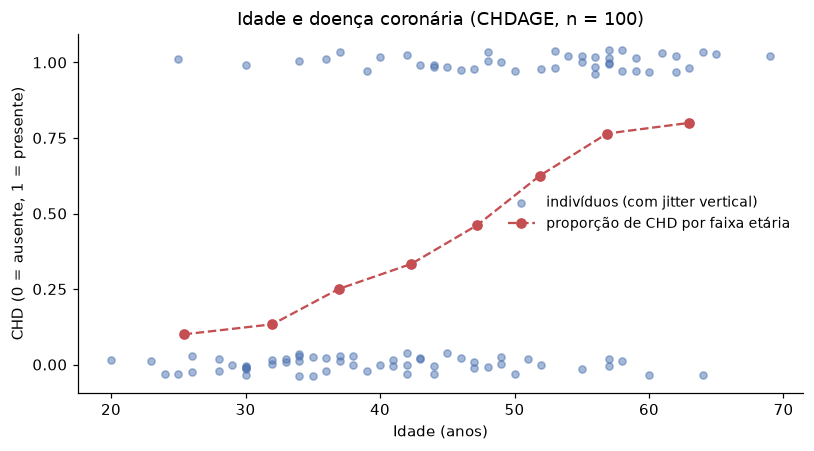

In [6]:
rng = np.random.default_rng(23)  # semente fixa: o jitter fica igual a cada execução
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.scatter(chd_dados["age"], chd_dados["chd"] + rng.uniform(-0.04, 0.04, len(chd_dados)),
           alpha=0.5, s=22, color="#4C72B0", label="indivíduos (com jitter vertical)")
ax.plot(tab_faixa["idade_media"], tab_faixa["proporcao_chd"], "o--", color="#C44E52",
        label="proporção de CHD por faixa etária")
ax.set(xlabel="Idade (anos)", ylabel="CHD (0 = ausente, 1 = presente)",
       title="Idade e doença coronária (CHDAGE, n = 100)")
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.legend(loc="center right", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

A proporção de doentes cresce com a idade em forma de **S suave**, limitada entre 0 e 1. Uma reta
(regressão linear) não respeita esses limites e preveria probabilidades negativas ou maiores que 1 nos
extremos; além disso, a variância de um desfecho binário depende da própria média, violando a
homocedasticidade. Por isso usamos a regressão logística.

## 5. O modelo logístico

Seja $\pi(x) = P(\text{CHD} = 1 \mid \text{idade} = x)$. O modelo logístico simples supõe que o **logaritmo
da chance** (*log-odds*, ou *logit*) é linear na idade:

$$
\operatorname{logit}\,\pi(x) \;=\; \ln\!\left(\frac{\pi(x)}{1-\pi(x)}\right) \;=\; \beta_0 + \beta_1 x
\qquad\Longleftrightarrow\qquad
\pi(x) = \frac{e^{\beta_0+\beta_1 x}}{1+e^{\beta_0+\beta_1 x}}.
$$

Os parâmetros são estimados por **máxima verossimilhança** (não por mínimos quadrados). Duas formas
equivalentes no `statsmodels`:

- `smf.logit("chd ~ age", data)` — a mesma do post;
- `smf.glm("chd ~ age", data, family=sm.families.Binomial())` — o GLM com ligação logit, idêntico ao `glm()` do R.

Equivalente em R:

```r
modelo <- glm(chd ~ age, family = binomial(link = "logit"), data = chdage)
summary(modelo)
```

In [7]:
# Modelo 1: Logit (como no post)
modelo = smf.logit("chd ~ age", data=chd_dados).fit()
print(modelo.summary())

Optimization terminated successfully.
         Current function value: 0.536765
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                    chd   No. Observations:                  100
Model:                          Logit   Df Residuals:                       98
Method:                           MLE   Df Model:                            1
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                  0.2145
Time:                        19:41:23   Log-Likelihood:                -53.677
converged:                       True   LL-Null:                       -68.331
Covariance Type:            nonrobust   LLR p-value:                 6.168e-08
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -5.3095      1.134     -4.683      0.000      -7.531      -3.088
age            0.1109      0.

In [8]:
# Modelo 2: GLM Binomial (mesma estimativa, saída no estilo do glm() do R)
modelo_glm = smf.glm("chd ~ age", data=chd_dados, family=sm.families.Binomial()).fit()
print(modelo_glm.summary())

# Os coeficientes devem ser idênticos aos do Logit
print("\nDiferença máxima entre coeficientes Logit x GLM:",
      float(np.max(np.abs(modelo.params - modelo_glm.params))))

                 Generalized Linear Model Regression Results                  
Dep. Variable:                    chd   No. Observations:                  100
Model:                            GLM   Df Residuals:                       98
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -53.677
Date:                Mon, 09 Nov 2026   Deviance:                       107.35
Time:                        19:41:23   Pearson chi2:                     102.
No. Iterations:                     4   Pseudo R-squ. (CS):             0.2541
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -5.3095      1.134     -4.683      0.0

### 5.1 Lendo a saída

| Termo | Coeficiente (β) | EP | z | p |
|---|---|---|---|---|
| Intercepto | −5,3095 | 1,134 | −4,68 | < 0,001 |
| Idade | 0,1109 | 0,024 | 4,61 | < 0,001 |

Esses valores batem exatamente com os do post (e com a Tabela 1.3 de Hosmer, Lemeshow & Sturdivant).

- **β₁ = 0,1109** é a variação no **log-odds** de CHD a cada ano a mais de idade. O sinal positivo indica
  que a chance de doença aumenta com a idade.
- **β₀ = −5,31** é o log-odds de CHD para idade = 0 — uma extrapolação sem sentido clínico (ninguém da
  amostra tem menos de 20 anos). Se quiséssemos um intercepto interpretável, bastaria **centrar** a idade
  (por exemplo, em 45 anos).
- O **p-valor de Wald** (< 0,001) testa H₀: β₁ = 0. Ele diz que os dados são pouco compatíveis com
  ausência de associação; não diz, por si só, que a associação é grande, causal ou útil para prever.
- **Pseudo-R² de McFadden = 0,21** e log-verossimilhança −53,68 (contra −68,33 do modelo só com
  intercepto). O pseudo-R² **não** é a "proporção de variância explicada" da regressão linear; serve mais
  para comparar modelos ajustados aos mesmos dados.

### 5.2 Teste da razão de verossimilhanças

Em regressão logística, o teste preferido para H₀: β₁ = 0 é o da **razão de verossimilhanças (LR)**, que
compara o modelo com idade ao modelo nulo. Em amostras pequenas ele costuma se comportar melhor que o de Wald.

$$
G = 2\,[\ell(\text{modelo}) - \ell(\text{nulo})] \;\sim\; \chi^2_{1} \text{ sob } H_0 .
$$

In [9]:
G = 2 * (modelo.llf - modelo.llnull)
p_lr = stats.chi2.sf(G, df=1)
print(f"log-verossimilhança do modelo: {modelo.llf:.3f}")
print(f"log-verossimilhança do nulo:   {modelo.llnull:.3f}")
print(f"G = {G:.2f}  (gl = 1)   p = {p_lr:.2e}")
print(f"Conferência com o statsmodels: LLR = {modelo.llr:.2f}, p = {modelo.llr_pvalue:.2e}")

log-verossimilhança do modelo: -53.677
log-verossimilhança do nulo:   -68.331
G = 29.31  (gl = 1)   p = 6.17e-08
Conferência com o statsmodels: LLR = 29.31, p = 6.17e-08


$G \approx 29{,}31$ com 1 grau de liberdade ($p \approx 6{,}2 \times 10^{-8}$; é o `LLR p-value` do resumo).
Em R: `anova(modelo, test = "LRT")` ou `drop1(modelo, test = "LRT")`.

## 6. Razão de chances (OR) e intervalo de confiança

Como o modelo é linear no log-odds, exponenciar o coeficiente transforma a diferença de log-odds em
**razão de chances**:

$$
\mathrm{OR}_{+1\ \text{ano}} = \frac{\text{odds}(x+1)}{\text{odds}(x)} = e^{\beta_1},
\qquad
\mathrm{OR}_{+c\ \text{anos}} = e^{c\,\beta_1}.
$$

O IC 95% da OR é obtido exponenciando os limites do IC de β (nunca calculando "OR ± 1,96·EP").

In [10]:
# OR e IC 95% de Wald: exponenciar coeficiente e limites
tabela_or = pd.DataFrame({
    "beta": modelo.params,
    "OR": np.exp(modelo.params),
    "IC95_inf": np.exp(modelo.conf_int()[0]),
    "IC95_sup": np.exp(modelo.conf_int()[1]),
})
print(tabela_or.round(4))

or_idade = tabela_or.loc["age", "OR"]
print(f"\nVariação percentual na chance por ano de idade: {(or_idade - 1) * 100:.2f}%")

             beta      OR  IC95_inf  IC95_sup
Intercept -5.3095  0.0049    0.0005    0.0456
age        0.1109  1.1173    1.0658    1.1713

Variação percentual na chance por ano de idade: 11.73%


**Interpretação (por ano).** Cada ano adicional de idade multiplica a **chance** (*odds*) de CHD por
**1,117** (IC 95%: 1,066 a 1,171), isto é, um aumento de cerca de **11,7%** na chance por ano. Os números
coincidem com os do post (OR ≈ 1,11 arredondado; 11,73%; IC 1,06 a 1,17).

Dois cuidados de linguagem:

- É aumento na **chance**, não na **probabilidade**. "A probabilidade de CHD aumenta 11,7% por ano" está
  errado — e veremos na seção 8 que, aqui, a diferença é grande.
- Sobre o IC: o correto é dizer que o **procedimento** gera intervalos que, em repetições hipotéticas do
  estudo, conteriam o valor verdadeiro em 95% das vezes. Na prática, o IC mostra a faixa de valores de OR
  compatíveis com os dados — todos acima de 1 aqui, e de magnitude modesta a moderada por ano.

### 6.1 Uma unidade clinicamente mais útil: 10 anos

"Um ano a mais" é uma unidade pequena para idade. A OR para uma diferença de 10 anos é $e^{10\beta_1}$, e
o IC sai exponenciando $10 \times$ os limites do IC de β₁ (a OR por década **não** é 10 × 1,117).

In [11]:
c = 10
b1, (li, ls) = modelo.params["age"], modelo.conf_int().loc["age"]
print(f"OR para +{c} anos: {np.exp(c*b1):.2f}  (IC 95%: {np.exp(c*li):.2f} a {np.exp(c*ls):.2f})")

OR para +10 anos: 3.03  (IC 95%: 1.89 a 4.86)


Uma diferença de 10 anos de idade está associada a chance de CHD cerca de **3,0 vezes maior**
(IC 95%: 1,9 a 4,9).

### 6.2 IC por verossimilhança perfilada (o que o R entrega por padrão)

O `conf_int()` do `statsmodels` dá o **IC de Wald** (β ± 1,96·EP). Já o `confint()` do R, para `glm`, dá o
**IC por verossimilhança perfilada**, que não supõe simetria na escala de β e costuma ser mais confiável em
amostras pequenas ou com coeficientes grandes. Por isso os ICs de um mesmo modelo podem diferir um pouco
entre R e Python. Abaixo, o perfil de β₁ calculado à mão: para cada valor candidato de β₁, reajusta-se só o
intercepto e procura-se onde a queda na log-verossimilhança atinge $\chi^2_{1;\,0,95}/2 \approx 1{,}92$.

```r
exp(confint(modelo))          # IC perfilado (padrão do R)
exp(confint.default(modelo))  # IC de Wald (igual ao statsmodels)
```

In [12]:
y = chd_dados["chd"].to_numpy()
x = chd_dados["age"].to_numpy(dtype=float)
const = np.ones_like(x)
limiar = stats.chi2.ppf(0.95, df=1) / 2

def queda_loglik(b1_fixo):
    # log-verossimilhança com beta1 fixo (offset) e intercepto livre, comparada ao máximo
    m = sm.GLM(y, const, family=sm.families.Binomial(), offset=b1_fixo * x).fit()
    return modelo.llf - m.llf - limiar

b1_hat, ep = modelo.params["age"], modelo.bse["age"]
lim_inf = optimize.brentq(queda_loglik, b1_hat - 5 * ep, b1_hat)
lim_sup = optimize.brentq(queda_loglik, b1_hat, b1_hat + 5 * ep)

wald = np.exp(modelo.conf_int().loc["age"])
print(f"OR por ano — IC 95% Wald:      {wald[0]:.4f} a {wald[1]:.4f}")
print(f"OR por ano — IC 95% perfilado: {np.exp(lim_inf):.4f} a {np.exp(lim_sup):.4f}")

OR por ano — IC 95% Wald:      1.0658 a 1.1713
OR por ano — IC 95% perfilado: 1.0692 a 1.1759


Neste banco os dois intervalos praticamente coincidem (Wald 1,066–1,171; perfilado 1,069–1,176) — o que é esperado com n = 100, 43 eventos e um
efeito moderado. A diferença ganha importância com poucos eventos ou quando há quase-separação.

## 7. Probabilidades preditas

O modelo devolve a probabilidade estimada de CHD para qualquer idade. O post calcula a predição para a idade
média da amostra:

In [13]:
idade_media = chd_dados["age"].mean()
p_media = modelo.predict(pd.DataFrame({"age": [idade_media]}))[0]
print(f"Idade média: {idade_media:.2f} anos -> probabilidade predita de CHD = {p_media:.4f} ({p_media:.2%})")

# Conferência "na mão": pi = 1 / (1 + exp(-(b0 + b1*x)))
b0, b1 = modelo.params
print("Conferência manual:", round(1 / (1 + np.exp(-(b0 + b1 * idade_media))), 4))

Idade média: 44.38 anos -> probabilidade predita de CHD = 0.4045 (40.45%)
Conferência manual: 0.4045


Para um indivíduo de 44,38 anos, a probabilidade estimada de CHD é **40,4%** — igual ao valor do post.

Uma predição pontual sem incerteza é meia informação. Usando o GLM, obtemos o IC 95% da probabilidade
predita (calculado na escala do logit e transformado de volta, o que garante limites entre 0 e 1) para
algumas idades e para a curva inteira.

In [14]:
idades = pd.DataFrame({"age": [30, 40, idade_media, 50, 60]})
pred = modelo_glm.get_prediction(idades).summary_frame(alpha=0.05)
tabela_pred = pd.DataFrame({
    "idade": idades["age"].round(2),
    "prob_CHD": pred["mean"],
    "IC95_inf": pred["mean_ci_lower"],
    "IC95_sup": pred["mean_ci_upper"],
})
tabela_pred.round(3)

,idade,prob_CHD,IC95_inf,IC95_sup
0,30.00,0.121,0.054,0.251
1,40.00,0.295,0.195,0.419
2,44.38,0.404,0.298,0.521
3,50.00,0.559,0.435,0.676
4,60.00,0.793,0.632,0.896


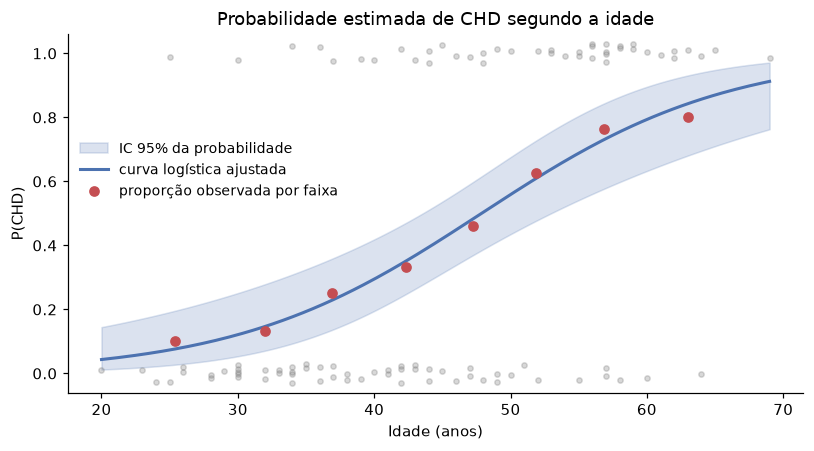

In [15]:
grade = pd.DataFrame({"age": np.linspace(20, 69, 200)})
curva = modelo_glm.get_prediction(grade).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.fill_between(grade["age"], curva["mean_ci_lower"], curva["mean_ci_upper"],
                color="#4C72B0", alpha=0.2, label="IC 95% da probabilidade")
ax.plot(grade["age"], curva["mean"], color="#4C72B0", lw=2, label="curva logística ajustada")
ax.plot(tab_faixa["idade_media"], tab_faixa["proporcao_chd"], "o", color="#C44E52",
        label="proporção observada por faixa")
ax.scatter(chd_dados["age"], chd_dados["chd"] + rng.uniform(-0.03, 0.03, len(chd_dados)),
           s=12, alpha=0.3, color="gray")
ax.set(xlabel="Idade (anos)", ylabel="P(CHD)", ylim=(-0.06, 1.06),
       title="Probabilidade estimada de CHD segundo a idade")
ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.62), frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

A curva ajustada acompanha bem as proporções observadas por faixa etária — um primeiro sinal, ainda
informal, de que a forma logística na idade contínua é razoável. A avaliação formal de ajuste (por exemplo,
Hosmer–Lemeshow, calibração) e de discriminação (curva ROC/AUC) fica para os próximos casos.

## 8. Cuidado: razão de chances não é risco relativo

A chance (*odds*) é $\pi/(1-\pi)$; o risco é $\pi$. Quando o desfecho é **raro** (digamos, < 10%),
$\pi/(1-\pi) \approx \pi$ e a OR se aproxima do risco relativo (RR). Quando o desfecho é **frequente** —
como aqui, 43% de prevalência — a OR **exagera** o RR (fica mais distante de 1).

Comparemos, com o próprio modelo, um indivíduo de 50 anos com um de 40 anos:

In [16]:
p40, p50 = modelo.predict(pd.DataFrame({"age": [40, 50]}))
odds40, odds50 = p40 / (1 - p40), p50 / (1 - p50)
print(f"P(CHD | 40 anos) = {p40:.3f}   odds = {odds40:.3f}")
print(f"P(CHD | 50 anos) = {p50:.3f}   odds = {odds50:.3f}")
print(f"\nOR (50 vs 40) = {odds50/odds40:.2f}   (= exp(10*beta1) = {np.exp(10*b1):.2f})")
print(f"RR (50 vs 40) = {p50/p40:.2f}")
print(f"Diferença de risco = {p50 - p40:.3f}  ({(p50 - p40)*100:.1f} pontos percentuais)")

P(CHD | 40 anos) = 0.295   odds = 0.418
P(CHD | 50 anos) = 0.559   odds = 1.267

OR (50 vs 40) = 3.03   (= exp(10*beta1) = 3.03)
RR (50 vs 40) = 1.90
Diferença de risco = 0.264  (26.4 pontos percentuais)


A OR para 50 × 40 anos é cerca de **3,0**, mas a probabilidade de CHD sobe de cerca de 30% (29,5%) para 56% (55,9%) — um
**RR de aproximadamente 1,9** e uma diferença de risco de 26 pontos percentuais. Dizer que "quem tem 50 anos tem 3 vezes mais risco" seria um erro de
interpretação comum (e frequente na literatura médica).

Pontos a reter:

- A OR do modelo logístico é **constante** ao longo da idade; o RR e a diferença de risco **não** são — dependem
  da faixa em que se compara.
- Para comunicar a pacientes ou em decisões clínicas, probabilidades preditas e diferenças de risco costumam
  ser mais intuitivas que a OR.
- Quando o RR é o parâmetro de interesse em estudos com desfecho frequente, há alternativas diretas, como
  regressão log-binomial ou Poisson com variância robusta.

## 9. Conferência com o post da Statplace

| Quantidade | Post | Este notebook |
|---|---|---|
| n; casos de CHD | 100; 43 | 100; 43 |
| Idade média (mín.–máx.) | 44,38 (20–69) | 44,38 (20–69) |
| β₀ (EP) | −5,3095 (1,134) | −5,3095 (1,134) |
| β₁ (EP) | 0,1109 (0,024) | 0,1109 (0,024) |
| Pseudo-R²; log-verossimilhança | 0,2145; −53,677 | 0,2145; −53,677 |
| OR por ano (IC 95%) | 1,117 (1,066–1,171) | 1,117 (1,066–1,171) |
| Variação na chance por ano | 11,73% | 11,73% |
| P(CHD) na idade média | 40,44% | 40,45% |

Todos os números batem. A única diferença é de arredondamento na última linha: a probabilidade exata é
0,40449…, que o post apresenta truncada como 40,44%.

Diferenças de método e de texto em relação ao post:

- **Leitura do `.rda`** com `pyreadr` em vez de `rpy2` (dispensa o R instalado); a recodificação é feita pelo
  rótulo `No`/`Yes`, com conferência.
- O post afirma que os p-valores pequenos "indicam que as variáveis têm relevância para o modelo". O p-valor
  do intercepto testa apenas β₀ = 0 (log-odds nulo aos 0 anos) e não tem interesse aqui; e significância
  estatística não equivale a relevância clínica nem a bom desempenho preditivo.
- O post diz que a OR de 1,11 significa que "as chances aumentam 1,11 vezes" a cada ano. Mais preciso:
  as chances são **multiplicadas** por 1,117 (aumento de 11,7%).
- Acrescentamos: teste da razão de verossimilhanças, OR por década, IC perfilado, predições com IC e a
  discussão OR × RR.

## 10. Resumo

- **Modelo:** $\operatorname{logit}\,P(\text{CHD}) = -5{,}31 + 0{,}111 \times \text{idade}$ (n = 100; 43 eventos).
- **Associação:** cada ano de idade multiplica a chance de CHD por 1,117 (IC 95%: 1,066–1,171); por década,
  OR ≈ 3,0 (IC 95%: 1,9–4,9). Teste LR: G = 29,3, p < 0,001.
- **Predição:** na idade média (44,4 anos), P(CHD) ≈ 40%; sobe de ≈ 30% aos 40 para ≈ 56% aos 50 anos.
- **Interpretação:** OR fala de **chance**, não de probabilidade; com desfecho frequente, OR ≠ RR (aqui,
  OR ≈ 3,0 contra RR ≈ 1,9 entre 50 e 40 anos).
- **Limites:** amostra pequena e um único preditor — nada de causalidade ou de ajuste por confundidores;
  ajuste e discriminação ainda não foram avaliados.

## 11. Exercícios

1. **Centralização.** Crie `idade_c = age - 45` e reajuste o modelo. O que muda em β₀ e em β₁? Interprete
   o novo intercepto em termos de probabilidade.
2. **OR para 5 anos.** Calcule a OR e o IC 95% para uma diferença de 5 anos de idade.
3. **Faixa etária como categoria.** Ajuste `chd ~ C(agegrp)`. Compare as ORs de cada faixa contra a primeira
   e discuta o custo (graus de liberdade, precisão) de categorizar uma variável contínua.
4. **OR × RR.** Repita a comparação da seção 8 para 30 × 20 anos e para 65 × 55 anos. Em qual faixa a OR
   se aproxima mais do RR? Por quê?
5. **Probabilidade-alvo.** A partir dos coeficientes, encontre a idade em que a probabilidade predita de CHD
   é 50% (dica: $\pi = 0{,}5 \Leftrightarrow \beta_0 + \beta_1 x = 0$).
6. **Para ir além.** Calcule a AUC (área sob a curva ROC) das probabilidades preditas com
   `sklearn.metrics.roc_auc_score` e interprete o valor como capacidade de discriminação.

## Referências

- GOUVEIA, P. *Regressão Logística Simples: Aplicação no Python (Caso 1)*. Statplace, 25 fev. 2025.
  Disponível em: <https://statplace.com.br/blog/regressao-logistica-caso1/>.
- HOSMER, D. W.; LEMESHOW, S.; STURDIVANT, R. X. *Applied Logistic Regression*. 3. ed. Hoboken: Wiley, 2013.
- AGRESTI, A. *An Introduction to Categorical Data Analysis*. 2. ed. Hoboken: Wiley, 2007.
- BRAGLIA, L. *aplore3: Datasets from Hosmer, Lemeshow and Sturdivant, "Applied Logistic Regression" (3rd ed.)*.
  Pacote R. <https://github.com/lbraglia/aplore3>.
- ZHANG, J.; YU, K. F. What's the relative risk? A method of correcting the odds ratio in cohort studies of
  common outcomes. *JAMA*, v. 280, n. 19, p. 1690–1691, 1998.